# ПРАКТИЧЕСКОЕ ЗАДАНИЕ 4. АНАЛИЗ ВРЕМЕННОГО РЯДА

В данной практике будут использоваться спаршенные в первой практической даннные о среднемедианной температуре в сиднее с февраля 2017 по сентябрь 2026 

Зазгрузим набор данны в df

In [2]:
import pandas as pd

df = pd.read_csv("Sydney_mean_temp_decade.csv")

df.head()

,time,temperature_2m_mean
0,2017-01-02,21.7
1,2017-01-03,20.7
2,2017-01-04,21.4
3,2017-01-05,21.7
4,2017-01-06,22.1


После загрузки данных следует построить первичный график временного ряда,
чтобы визуально оценить его динамику, наличие тренда, резких скачков,
выбросов, сезонности или повторяющихся колебаний.

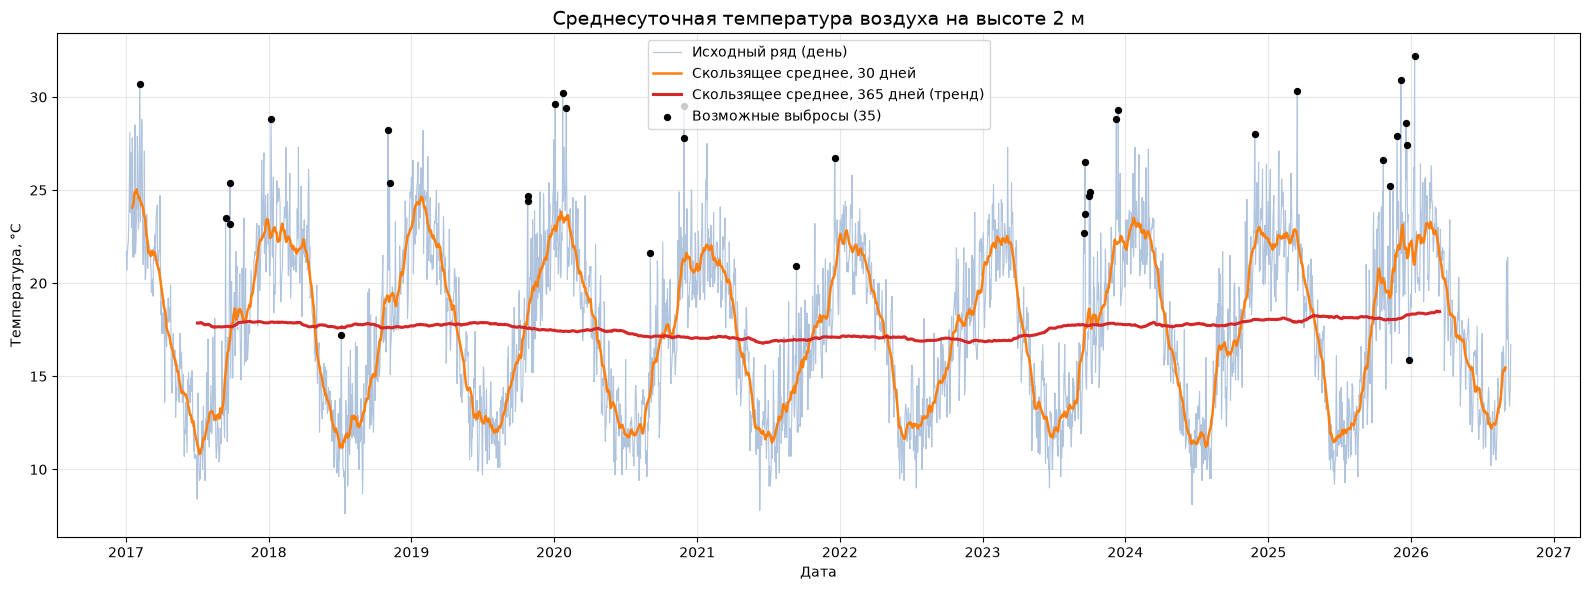

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

df['time'] = pd.to_datetime(df['time'])
ts = df.set_index('time')['temperature_2m_mean'].sort_index()

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(ts.index, ts.values, color='lightsteelblue', lw=0.8, label='Исходный ряд (день)')
ax.plot(ts.rolling(30, center=True).mean(), color='tab:orange', lw=1.8, label='Скользящее среднее, 30 дней')
ax.plot(ts.rolling(365, center=True).mean(), color='tab:red', lw=2.2, label='Скользящее среднее, 365 дней (тренд)')

resid = ts - ts.rolling(30, center=True).mean()
outliers = ts[resid.abs() > 3 * resid.std()]
ax.scatter(outliers.index, outliers.values, color='black', s=18, zorder=5,
           label=f'Возможные выбросы ({len(outliers)})')

ax.set_title('Среднесуточная температура воздуха на высоте 2 м', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Частота отсечки: 0.09402 цикл/мес, период ≈ 11 мес.


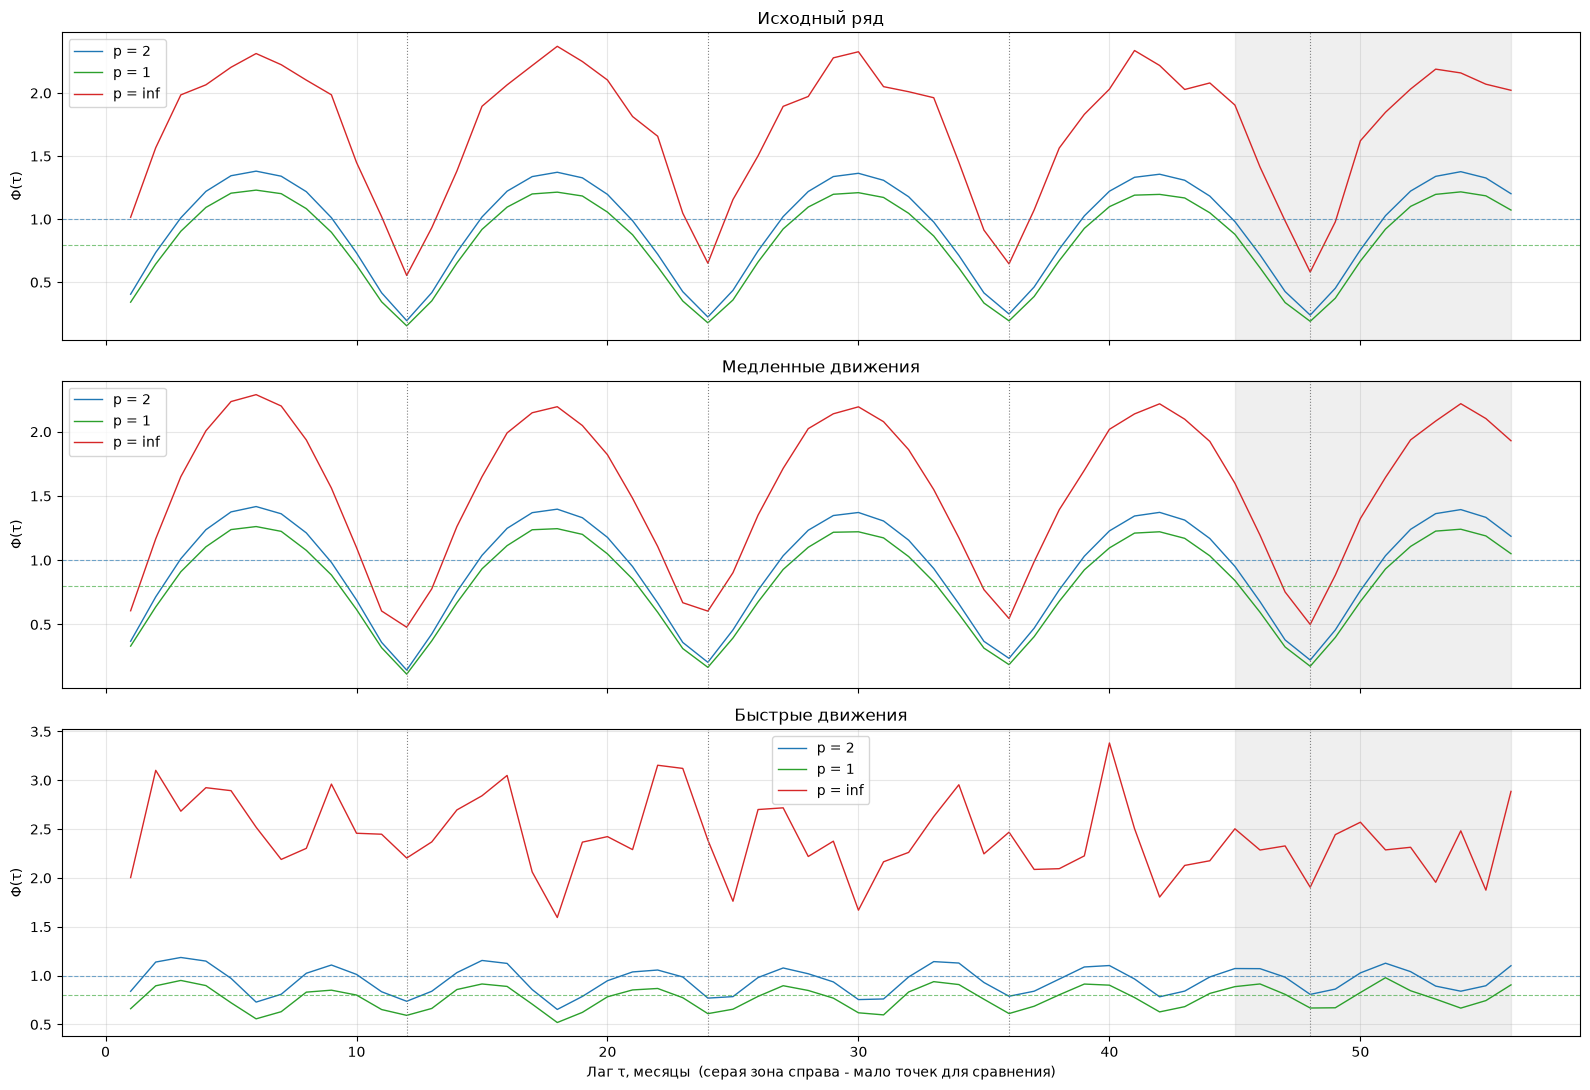


Медленные движения, Φ_2: минимумы около 12·k
 k  лаг τ_k  Φ в минимуме  период τ_k/k
 1       12         0.145          12.0
 2       24         0.206          12.0
 3       36         0.236          12.0
 4       48         0.223          12.0

Медленные движения, Φ_inf: минимумы около 12·k
 k  лаг τ_k  Φ в минимуме  период τ_k/k
 1       12         0.479          12.0
 2       24         0.604          12.0
 3       36         0.546          12.0
 4       48         0.500          12.0

ε-почти периоды медленной компоненты: τ_k - ε_k-почти период
 k  лаг τ_k  ε (в долях √2·σ)  ε, °C
 1       12             0.479   2.59
 2       24             0.604   3.26
 3       36             0.546   2.95
 4       48             0.500   2.70

Допуск ε = 0.55. Лаги, удовлетворяющие ему: [12, 36, 48]

Быстрые движения: порог значимости Φ_2 < 0.867
Значимые лаги: [6, 7, 11, 12, 13, 17, 18, 19, 24, 25, 30, 31, 36, 37, 42, 43, 48, 49, 54]

Исходный ряд: лучшие локальные минимумы Φ_2

Медленные движени

In [36]:
from scipy.signal import find_peaks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def shift_function(x, max_lag, p=2):
    """Нормированная обобщённая сдвиговая функция Φ_p(τ), τ = 1..max_lag."""
    x = np.asarray(x, float)
    x = x - x.mean()
    sigma = x.std()
    out = np.empty(max_lag)
    for i, tau in enumerate(range(1, max_lag + 1)):
        d = np.abs(x[tau:] - x[:-tau])
        out[i] = d.max() if np.isinf(p) else (d ** p).mean() ** (1 / p)
    return pd.Series(out / (np.sqrt(2) * sigma), index=np.arange(1, max_lag + 1),
                     name=f'Phi_p={p}')

# ---------- настройки (переведены в месяцы) ----------
TRIM   = 2       # обрезка краёв от краевых искажений FFT, МЕСЯЦЫ (было 60 дней)
HALF   = 2       # полуширина окна поиска минимума вокруг 12*k, МЕСЯЦЫ (было 40 дней)
N_SURR = 30      # число суррогатных рядов для порога значимости быстрых

# Преобразование данных в ежемесячные
df['time'] = pd.to_datetime(df['time'])
ts = df.set_index('time')['temperature_2m_mean'].sort_index()
# Усредняем по месяцам ('MS' - начало месяца) и интерполируем пропуски
ts = ts.resample('MS').mean().interpolate()

# 2. Спектр
x = ts.values - ts.values.mean()
N = len(x)
X = np.fft.rfft(x)
freqs = np.fft.rfftfreq(N, d=1.0)            # циклов в МЕСЯЦ
power = np.abs(X) ** 2

# 3. Граница по пропорции накопленной энергии
P = 0.90                                      # доля дисперсии, относимая к медленным движениям
cum_share = np.cumsum(power[1:]) / power[1:].sum()
k_cut = np.searchsorted(cum_share, P) + 1     # индекс частоты отсечки
f_cut = freqs[k_cut]
print(f'Частота отсечки: {f_cut:.5f} цикл/мес, период ≈ {1/f_cut:.0f} мес.')

# 4. Разделение
X_slow = X.copy(); X_slow[k_cut + 1:] = 0
slow = np.fft.irfft(X_slow, n=N) + ts.values.mean()
slow = pd.Series(slow, index=ts.index)
fast = ts - slow


# ---------- 0. Обрезка краёв ----------
ts_c, slow_c, fast_c = ts.iloc[TRIM:-TRIM], slow.iloc[TRIM:-TRIM], fast.iloc[TRIM:-TRIM]
series = {'Исходный ряд': ts_c, 'Медленные движения': slow_c, 'Быстрые движения': fast_c}
max_lag = int(len(ts_c) * 0.5)
reliable = int(len(ts_c) * 0.4)          # дальше лаги опираются на мало точек
noise_ref = {2: 1.0, 1: np.sqrt(2 / np.pi)}

# ---------- 1. Φ_2, Φ_1, Φ_inf для каждой компоненты ----------
fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
results = {}
for ax, (name, s) in zip(axes, series.items()):
    for p, c in [(2, 'tab:blue'), (1, 'tab:green'), (np.inf, 'tab:red')]:
        phi = shift_function(s.values, max_lag, p)
        results[(name, p)] = phi
        ax.plot(phi.index, phi.values, color=c, lw=1, label=f'p = {p}')
    for p, c in [(2, 'tab:blue'), (1, 'tab:green')]:          # уровень белого шума
        ax.axhline(noise_ref[p], color=c, ls='--', lw=0.8, alpha=0.6)
    for k in range(1, max_lag // 12 + 1):                     # ЗДЕСЬ 365 заменено на 12
        ax.axvline(12 * k, color='gray', ls=':', lw=0.8)
    ax.axvspan(reliable, max_lag, color='gray', alpha=0.12)    # ненадёжный хвост
    ax.set_title(name); ax.set_ylabel('Φ(τ)'); ax.grid(alpha=0.3); ax.legend()
axes[-1].set_xlabel('Лаг τ, месяцы  (серая зона справа - мало точек для сравнения)')
plt.tight_layout(); plt.show()

# ---------- 2. Уточнение периода по медленной компоненте ----------
def refine_minima(phi, base=12, half=HALF): # ЗДЕСЬ base=365 заменено на 12
    rows = []
    for k in range(1, int(phi.index.max() // base) + 1):
        lo, hi = base * k - half, min(base * k + half, phi.index.max())
        if lo < 1 or lo >= hi:
            continue
        w = phi.loc[lo:hi]
        rows.append({'k': k, 'лаг τ_k': int(w.idxmin()), 'Φ в минимуме': round(w.min(), 3),
                     'период τ_k/k': round(w.idxmin() / k, 1)})
    return pd.DataFrame(rows)

for p in (2, np.inf):
    print(f'\nМедленные движения, Φ_{p}: минимумы около 12·k')
    print(refine_minima(results[('Медленные движения', p)]).to_string(index=False))

# ---------- 3. ε-почти периоды (по sup-норме) ----------
phi_inf = results[('Медленные движения', np.inf)]
tab = refine_minima(phi_inf)
tab['ε (в долях √2·σ)'] = tab['Φ в минимуме']              # ε_k = Φ_∞(τ_k)
tab['ε, °C'] = (tab['ε (в долях √2·σ)'] * np.sqrt(2) * slow_c.std()).round(2)
print('\nε-почти периоды медленной компоненты: τ_k - ε_k-почти период')
print(tab[['k', 'лаг τ_k', 'ε (в долях √2·σ)', 'ε, °C']].to_string(index=False))

# ЗДЕСЬ 365 заменено на 12
eps = phi_inf.loc[12 - HALF:12 + HALF].min() * 1.15       # допуск относительно лучшего минимума
eps_lags = phi_inf.index[phi_inf < eps]
print(f'\nДопуск ε = {eps:.2f}. Лаги, удовлетворяющие ему: {list(eps_lags[:30])}')

# ---------- 4. Значимость минимумов быстрых движений (суррогаты) ----------
rng = np.random.default_rng(0)
fx = fast_c.values
sur = np.array([shift_function(rng.permutation(fx), max_lag, 2).values for _ in range(N_SURR)])
thr = np.percentile(sur, 1)                                # порог: 1-й процентиль шумового Φ_2
phi_fast = results[('Быстрые движения', 2)]
# лаги < 1 месяца отброшены (было 10 дней)
sig = phi_fast[(phi_fast.index > 1) & (phi_fast < thr)]   
print(f'\nБыстрые движения: порог значимости Φ_2 < {thr:.3f}')
print('Значимые лаги:', list(sig.index) if len(sig) else 'нет - ряд неотличим от шума по периодичности')

# ---------- 5. Минимумы для справки ----------
for name in series:
    print(f'\n{name}: лучшие локальные минимумы Φ_2')
    if 'almost_periods' in globals():
        print(almost_periods(results[(name, 2)]).round(3).to_string(index=False))

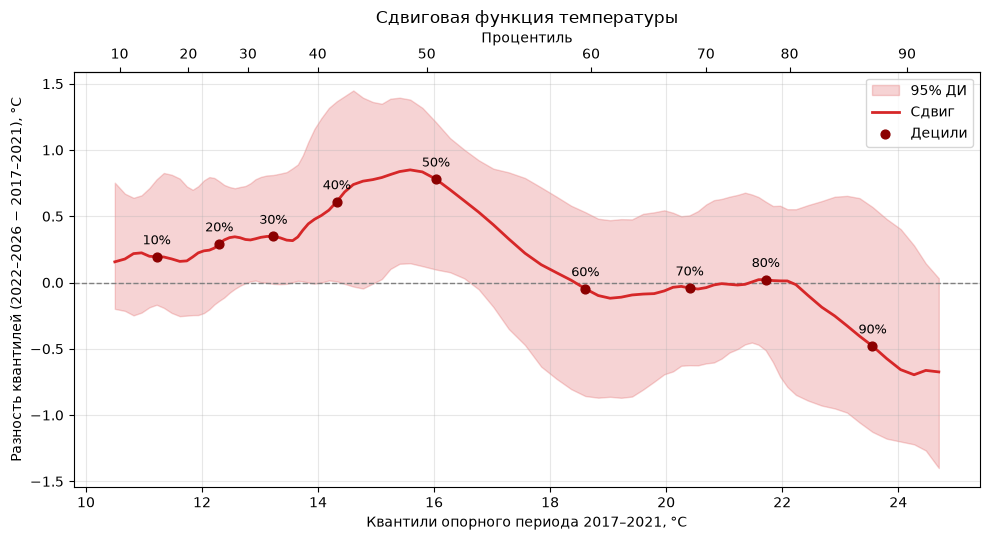

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats.mstats import hdquantiles

# ---------- параметры ----------
s = ts.dropna()
months = None            # None = весь год; [12,1,2] = зима, [6,7,8] = лето
if months is not None:
    s = s[s.index.month.isin(months)]

# 2026 неполный: чтобы не искажать сезонный состав, оставляем только дни года,
# которые есть в последнем году
last = s.index.max()
cutoff = (last.month, last.day)
s = s[[(d.month, d.day) <= cutoff for d in s.index]]

years = np.sort(s.index.year.unique())
mid = len(years) // 2
period1 = (years[0], years[mid - 1])
period2 = (years[mid], years[-1])

probs = np.arange(0.05, 0.951, 0.01)     # сетка квантилей для гладкой кривой
n_boot = 1000
rng = np.random.default_rng(42)

def by_year(a, b):
    sub = s[(s.index.year >= a) & (s.index.year <= b)]
    return [g.values for _, g in sub.groupby(sub.index.year)]

g1, g2 = by_year(*period1), by_year(*period2)
x, y = np.concatenate(g1), np.concatenate(g2)

def diff(a, b):
    return hdquantiles(b, prob=probs).data - hdquantiles(a, prob=probs).data

observed = diff(x, y)

def resample(groups):
    idx = rng.integers(0, len(groups), len(groups))
    return np.concatenate([groups[i] for i in idx])

boot = np.array([diff(resample(g1), resample(g2)) for _ in range(n_boot)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

# ---------- график ----------
# ... всё до блока "график" без изменений ...

# ---------- график ----------
q1 = hdquantiles(x, prob=probs).data
deciles = np.arange(0.1, 0.91, 0.1)
q_dec = hdquantiles(x, prob=deciles).data          # значения децилей периода 1
obs_dec = np.interp(q_dec, q1, observed)           # сдвиг в точках децилей

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axhline(0, color='gray', ls='--', lw=1)
ax.fill_between(q1, lo, hi, color='tab:red', alpha=0.2, label='95% ДИ')
ax.plot(q1, observed, color='tab:red', lw=2, label='Сдвиг')
ax.scatter(q_dec, obs_dec, color='darkred', s=40, zorder=5, label='Децили')

for p, qx, d in zip(deciles, q_dec, obs_dec):
    ax.annotate(f'{int(round(p*100))}%', (qx, d), textcoords='offset points',
                xytext=(0, 9), ha='center', fontsize=9)

# вторая ось сверху: процентили
sec = ax.secondary_xaxis('top',
        functions=(lambda v: np.interp(v, q1, probs * 100),
                   lambda p: np.interp(p, probs * 100, q1)))
sec.set_xticks([10, 20, 30, 40, 50, 60, 70, 80, 90])
sec.set_xlabel('Процентиль')

ax.set_xlabel(f'Квантили опорного периода {period1[0]}–{period1[1]}, °C')
ax.set_ylabel(f'Разность квантилей ({period2[0]}–{period2[1]} − {period1[0]}–{period1[1]}), °C')
ax.set_title('Сдвиговая функция температуры', pad=35)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

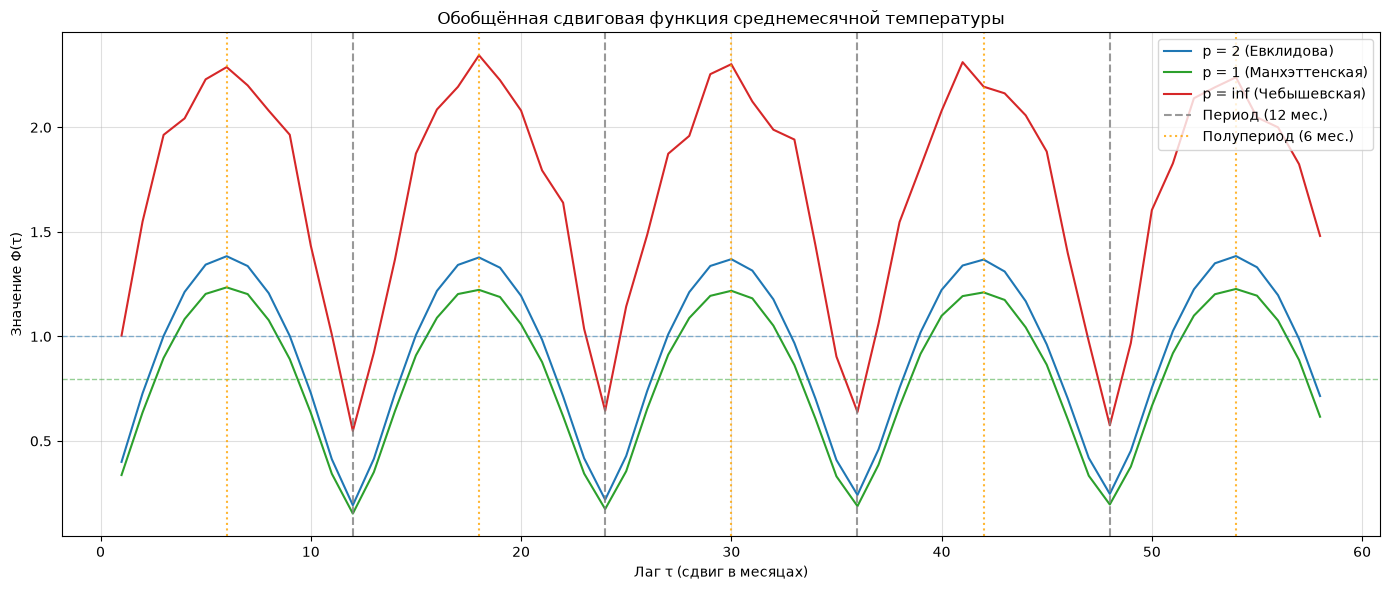

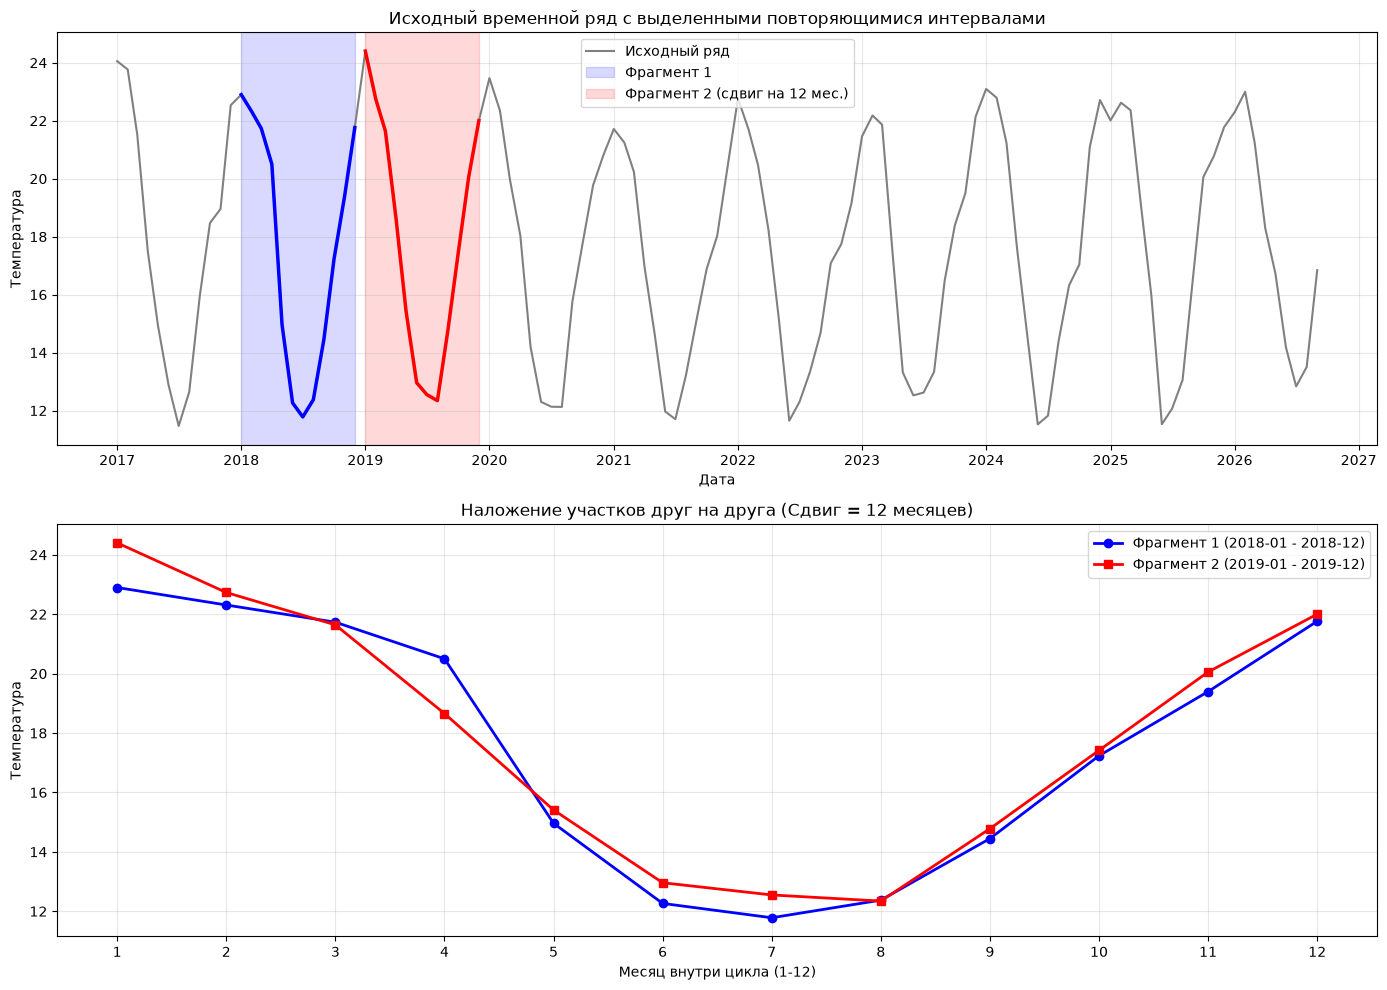

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =====================================================================
# 1. Функция расчета обобщенной сдвиговой функции
# =====================================================================
def shift_function(x, max_lag, p=2):
    x = np.asarray(x, float)
    x = x - x.mean()
    sigma = x.std()
    out = np.empty(max_lag)
    for i, tau in enumerate(range(1, max_lag + 1)):
        d = np.abs(x[tau:] - x[:-tau])
        out[i] = d.max() if np.isinf(p) else (d ** p).mean() ** (1 / p)
    return pd.Series(out / (np.sqrt(2) * sigma), index=np.arange(1, max_lag + 1), name=f'Phi_p={p}')

# =====================================================================
# 2. Загрузка и агрегация данных по месяцам
# =====================================================================
df = pd.read_csv("Sydney_mean_temp_decade.csv")
time_col = df.columns[0]
val_col = df.columns[1]

df[time_col] = pd.to_datetime(df[time_col])
df = df.set_index(time_col)
# Агрегируем по месяцам
ts = df[val_col].resample('MS').mean().interpolate()

# =====================================================================
# 3. Расчет сдвиговых функций
# =====================================================================
max_lag = int(len(ts) * 0.5)

phi_1 = shift_function(ts.values, max_lag, p=1)
phi_2 = shift_function(ts.values, max_lag, p=2)
phi_inf = shift_function(ts.values, max_lag, p=np.inf)

# =====================================================================
# 4. ВИЗУАЛИЗАЦИЯ 1: Сдвиговая функция
# =====================================================================
plt.figure(figsize=(14, 6))

plt.plot(phi_2.index, phi_2.values, label='p = 2 (Евклидова)', color='tab:blue', lw=1.5)
plt.plot(phi_1.index, phi_1.values, label='p = 1 (Манхэттенская)', color='tab:green', lw=1.5)
plt.plot(phi_inf.index, phi_inf.values, label='p = inf (Чебышевская)', color='tab:red', lw=1.5)

plt.axhline(1.0, color='tab:blue', ls='--', lw=1, alpha=0.5)
plt.axhline(np.sqrt(2 / np.pi), color='tab:green', ls='--', lw=1, alpha=0.5)

# Отмечаем годовые циклы (лаги 12, 24, 36...)
for k in range(1, max_lag // 12 + 1):
    plt.axvline(12 * k, color='gray', ls='--', lw=1.5, alpha=0.8, label='Период (12 мес.)' if k == 1 else "")

# Отмечаем полупериоды (лаги 6, 18, 30...)
for k in range(1, max_lag // 6 + 1):
    lag = 6 * k
    if lag % 12 != 0:
        plt.axvline(lag, color='orange', ls=':', lw=1.5, alpha=0.8, label='Полупериод (6 мес.)' if k == 1 else "")

plt.title("Обобщённая сдвиговая функция среднемесячной температуры")
plt.xlabel("Лаг τ (сдвиг в месяцах)")
plt.ylabel("Значение Φ(τ)")
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# =====================================================================
# 5. ВИЗУАЛИЗАЦИЯ 2: Наложение фрагментов
# =====================================================================
# Исходя из графиков выше, лучший лаг (период) = 12 месяцев
optimal_lag = 12 

# Выберем стартовую точку для выделения интервалов (например, 2-й год от начала)
start_idx = 12 

if start_idx + 2 * optimal_lag <= len(ts):
    # Вырезаем два последовательных участка длиной в optimal_lag
    frag1 = ts.iloc[start_idx : start_idx + optimal_lag]
    frag2 = ts.iloc[start_idx + optimal_lag : start_idx + 2 * optimal_lag]
    
    fig2 = plt.figure(figsize=(14, 10))
    
    # --- График 2.1: Исходный ряд с выделенными зонами ---
    ax1 = fig2.add_subplot(2, 1, 1)
    ax1.plot(ts.index, ts.values, color='gray', label='Исходный ряд', lw=1.5)
    
    # Заливка фоном выделенных участков
    ax1.axvspan(frag1.index[0], frag1.index[-1], color='blue', alpha=0.15, label='Фрагмент 1')
    ax1.axvspan(frag2.index[0], frag2.index[-1], color='red', alpha=0.15, label=f'Фрагмент 2 (сдвиг на {optimal_lag} мес.)')
    
    # Подсветка самих линий внутри зон
    ax1.plot(frag1.index, frag1.values, color='blue', lw=2.5)
    ax1.plot(frag2.index, frag2.values, color='red', lw=2.5)
    
    ax1.set_title("Исходный временной ряд с выделенными повторяющимися интервалами")
    ax1.set_xlabel("Дата")
    ax1.set_ylabel("Температура")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # --- График 2.2: Наложение участков друг на друга ---
    ax2 = fig2.add_subplot(2, 1, 2)
    
    # Создаем общую ось X (от 1 до optimal_lag) для идеального наложения
    x_overlay = np.arange(1, optimal_lag + 1)
    
    ax2.plot(x_overlay, frag1.values, marker='o', color='blue', lw=2, label=f'Фрагмент 1 ({frag1.index[0].strftime("%Y-%m")} - {frag1.index[-1].strftime("%Y-%m")})')
    ax2.plot(x_overlay, frag2.values, marker='s', color='red', lw=2, label=f'Фрагмент 2 ({frag2.index[0].strftime("%Y-%m")} - {frag2.index[-1].strftime("%Y-%m")})')
    
    ax2.set_title(f"Наложение участков друг на друга (Сдвиг = {optimal_lag} месяцев)")
    ax2.set_xlabel("Месяц внутри цикла (1-12)")
    ax2.set_ylabel("Температура")
    ax2.set_xticks(x_overlay)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Временной ряд слишком короткий для демонстрации наложения фрагментов по {optimal_lag} мес.")

In [37]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Убедимся, что ряд представлен в среднемесячных значениях ('MS' - начало месяца)
s = ts.resample('MS').mean().dropna()

# ---------- норма по месяцу из опорного периода ----------
base_years = (2017, 2021)
base = s[(s.index.year >= base_years[0]) & (s.index.year <= base_years[1])]

# Группируем по номеру месяца (1-12)
clim = base.groupby(base.index.month).mean().reindex(range(1, 13))

# ---------- аномалии ----------
# Вычитаем из каждого месяца его многолетнюю норму
anom = s - clim.reindex(s.index.month).values

# Скользящие средние (теперь в месяцах)
a3 = anom.rolling(3, center=True).mean()   # 3 месяца (аналог 30 дней)
a12 = anom.rolling(12, center=True).mean() # 12 месяцев (аналог 365 дней)

# ---------- график ----------
fig = go.Figure()

# Месячные аномалии
fig.add_trace(go.Scatter(
    x=anom.index, y=anom.values, mode='lines+markers', name='Аномалия (месяц)',
    line=dict(color='lightsteelblue', width=1),
    marker=dict(size=4),
    hovertemplate='%{y:.2f} °C'
))

# Заливка 3-месячного среднего: красная выше нуля, синяя ниже
fig.add_trace(go.Scatter(
    x=a3.index, y=a3.clip(lower=0), mode='lines', fill='tozeroy',
    line=dict(width=0), fillcolor='rgba(214,39,40,0.35)',
    showlegend=False, hoverinfo='skip'
))
fig.add_trace(go.Scatter(
    x=a3.index, y=a3.clip(upper=0), mode='lines', fill='tozeroy',
    line=dict(width=0), fillcolor='rgba(31,119,180,0.35)',
    showlegend=False, hoverinfo='skip'
))

# Линии скользящих средних
fig.add_trace(go.Scatter(
    x=a3.index, y=a3.values, mode='lines', name='Скользящее среднее, 3 мес.',
    line=dict(color='darkorange', width=2), hovertemplate='%{y:.2f} °C'
))
fig.add_trace(go.Scatter(
    x=a12.index, y=a12.values, mode='lines', name='Скользящее среднее, 12 мес.',
    line=dict(color='black', width=3), hovertemplate='%{y:.2f} °C'
))

# Нулевая линия и опорный период
fig.add_hline(y=0, line=dict(color='gray', width=1))
fig.add_vrect(
    x0=f'{base_years[0]}-01-01', x1=f'{base_years[1]}-12-31',
    fillcolor='gray', opacity=0.1, line_width=0,
    annotation_text=f'Опорный период {base_years[0]}–{base_years[1]}',
    annotation_position='top left'
)

fig.update_layout(
    title='Отклонение температуры от нормы по месяцам',
    xaxis=dict(title='Дата', rangeslider=dict(visible=True)),
    yaxis=dict(title='Аномалия, °C', zeroline=False),
    hovermode='x unified',
    template='plotly_white',
    height=550,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, x=0)
)

fig.show()

--- ОТЧЁТ ПО ТРЕНДОВЫМ ХАРАКТЕРИСТИКАМ (ШАГ = 1 НЕДЕЛЯ) ---

1. ИНТЕНСИВНЫЙ РОСТ (Экспоненциальный)
Границы участка: 2019-09-01 — 2019-12-31
Параметры: Скорость роста b = 0.0311, База ln(a) = -1.6709
Качество аппроксимации (R^2): 0.8918
Вывод: Линейность выражена явно. Модель экспоненциального роста подтверждается.

2. ОГРАНИЧЕННЫЙ РОСТ (Логистический)
Границы участка: 2022-09-01 — 2023-02-20
Возможный предельный уровень (K): 23.30
Параметры: r = 0.1182, ln(c) = 34.7047
Качество аппроксимации (R^2): 0.8127
Вывод: После преобразования точки близки к прямой. Модель ограниченного роста подтверждается.


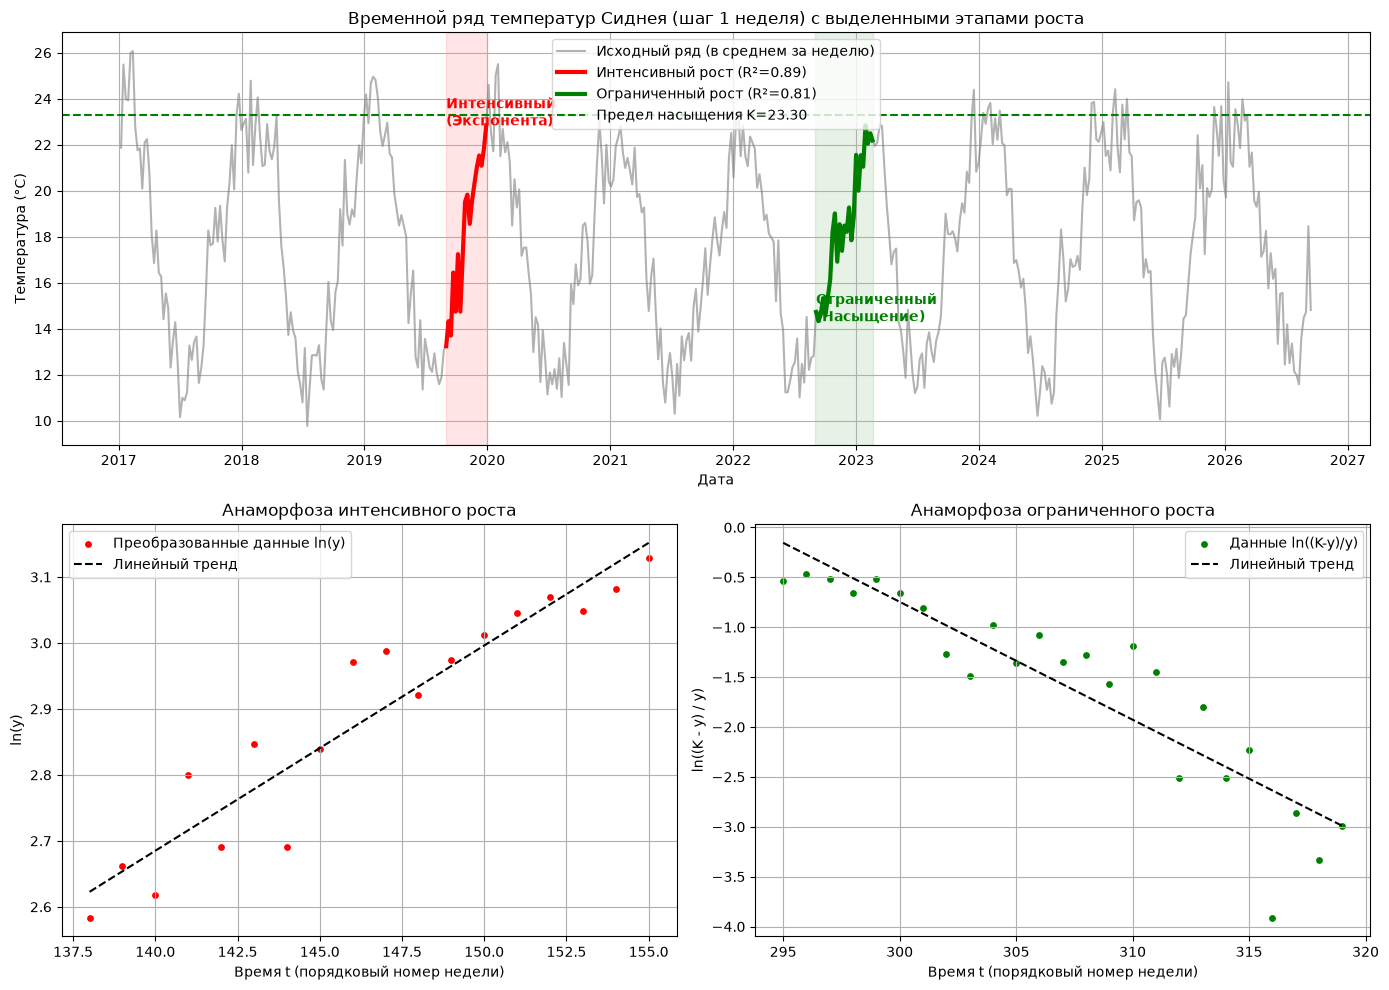

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. Загрузка и подготовка данных
df = pd.read_csv("Sydney_mean_temp_decade.csv")
time_col = df.columns[0] 
val_col = df.columns[1]  

# Преобразуем колонку времени в формат datetime
df[time_col] = pd.to_datetime(df[time_col])

# =====================================================================
# АГРЕГАЦИЯ: Усредняем данные по неделям ('W' - окончание недели)
# =====================================================================
df = df.set_index(time_col)
df = df.resample('W').mean().dropna() # Группировка по неделям
df = df.reset_index() # Сбрасываем индекс для получения порядкового шага

# =====================================================================
# ВАЖНО: Задайте здесь даты начала и конца в формате 'ГГГГ-ММ-ДД'
# =====================================================================
# Даты для интенсивного роста
date_int_start = '2019-09-01'
date_int_end   = '2019-12-31'

# Даты для ограниченного роста (замедление)
date_lim_start = '2022-09-01'
date_lim_end   = '2023-02-20'

# =====================================================================
# Выделение участков
# =====================================================================
start_int_dt = pd.to_datetime(date_int_start)
end_int_dt = pd.to_datetime(date_int_end)
start_lim_dt = pd.to_datetime(date_lim_start)
end_lim_dt = pd.to_datetime(date_lim_end)

mask_int = (df[time_col] >= start_int_dt) & (df[time_col] <= end_int_dt)
df_int = df[mask_int]

mask_lim = (df[time_col] >= start_lim_dt) & (df[time_col] <= end_lim_dt)
df_lim = df[mask_lim]

if df_int.empty:
    print(f"ВНИМАНИЕ: Нет данных для интенсивного роста в диапазоне {date_int_start} - {date_int_end}!")
if df_lim.empty:
    print(f"ВНИМАНИЕ: Нет данных для ограниченного роста в диапазоне {date_lim_start} - {date_lim_end}!")

t_int = df_int.index.values
y_int = df_int[val_col].values
dates_int = df_int[time_col].values

t_lim = df_lim.index.values
y_lim = df_lim[val_col].values
dates_lim = df_lim[time_col].values

dates_full = df[time_col].values
y_full = df[val_col].values

# =====================================================================
# 2. АНАЛИЗ ИНТЕНСИВНОГО РОСТА (Экспоненциальный)
# =====================================================================
if not df_int.empty:
    z_int = np.log(y_int) 
    slope_int, intercept_int, r_val_int, p_val_int, std_err_int = linregress(t_int, z_int)
    r2_int = r_val_int**2 

# =====================================================================
# 3. АНАЛИЗ ОГРАНИЧЕННОГО РОСТА (Логистический)
# =====================================================================
if not df_lim.empty:
    K = np.max(y_lim) * 1.02
    z_lim = np.log((K - y_lim) / y_lim)
    slope_lim, intercept_lim, r_val_lim, p_val_lim, std_err_lim = linregress(t_lim, z_lim)
    r2_lim = r_val_lim**2

# =====================================================================
# 4. ВЫВОД ОТЧЕТА В КОНСОЛЬ
# =====================================================================
print("--- ОТЧЁТ ПО ТРЕНДОВЫМ ХАРАКТЕРИСТИКАМ (ШАГ = 1 НЕДЕЛЯ) ---")
if not df_int.empty:
    print(f"\n1. ИНТЕНСИВНЫЙ РОСТ (Экспоненциальный)")
    print(f"Границы участка: {date_int_start} — {date_int_end}")
    print(f"Параметры: Скорость роста b = {slope_int:.4f}, База ln(a) = {intercept_int:.4f}")
    print(f"Качество аппроксимации (R^2): {r2_int:.4f}")
    if r2_int > 0.7:
        print("Вывод: Линейность выражена явно. Модель экспоненциального роста подтверждается.")
    else:
        print("Вывод: Линейность слабая. Данный участок плохо описывается интенсивным ростом.")

if not df_lim.empty:
    print(f"\n2. ОГРАНИЧЕННЫЙ РОСТ (Логистический)")
    print(f"Границы участка: {date_lim_start} — {date_lim_end}")
    print(f"Возможный предельный уровень (K): {K:.2f}")
    print(f"Параметры: r = {-slope_lim:.4f}, ln(c) = {intercept_lim:.4f}")
    print(f"Качество аппроксимации (R^2): {r2_lim:.4f}")
    if r2_lim > 0.7:
        print("Вывод: После преобразования точки близки к прямой. Модель ограниченного роста подтверждается.")
    else:
        print("Вывод: Линейность слабо выражена, модель насыщения не подходит.")

# =====================================================================
# 5. ВИЗУАЛИЗАЦИЯ
# =====================================================================
fig = plt.figure(figsize=(14, 10))

# График 1: Исходный временной ряд
ax1 = plt.subplot(2, 1, 1)
ax1.plot(dates_full, y_full, color='gray', linestyle='-', label='Исходный ряд (в среднем за неделю)', alpha=0.6)

if not df_int.empty:
    ax1.plot(dates_int, y_int, color='red', linewidth=3, label=f'Интенсивный рост (R²={r2_int:.2f})')
    ax1.axvspan(start_int_dt, end_int_dt, color='red', alpha=0.1)
    ax1.text(dates_int[0], np.max(y_int), 'Интенсивный\n(Экспонента)', color='red', fontsize=10, weight='bold')

if not df_lim.empty:
    ax1.plot(dates_lim, y_lim, color='green', linewidth=3, label=f'Ограниченный рост (R²={r2_lim:.2f})')
    ax1.axvspan(start_lim_dt, end_lim_dt, color='green', alpha=0.1)
    ax1.axhline(y=K, color='green', linestyle='--', label=f'Предел насыщения K={K:.2f}')
    ax1.text(dates_lim[0], np.min(y_lim), 'Ограниченный\n(Насыщение)', color='green', fontsize=10, weight='bold')

ax1.set_title("Временной ряд температур Сиднея (шаг 1 неделя) с выделенными этапами роста")
ax1.set_xlabel("Дата")
ax1.set_ylabel("Температура (°C)")
ax1.legend()
ax1.grid(True)

if not df_int.empty:
    ax2 = plt.subplot(2, 2, 3)
    ax2.scatter(t_int, z_int, color='red', s=15, label='Преобразованные данные ln(y)')
    ax2.plot(t_int, intercept_int + slope_int * t_int, color='black', linestyle='--', label='Линейный тренд')
    ax2.set_title("Анаморфоза интенсивного роста")
    ax2.set_xlabel("Время t (порядковый номер недели)")
    ax2.set_ylabel("ln(y)")
    ax2.legend()
    ax2.grid(True)

if not df_lim.empty:
    ax3 = plt.subplot(2, 2, 4)
    ax3.scatter(t_lim, z_lim, color='green', s=15, label='Данные ln((K-y)/y)')
    ax3.plot(t_lim, intercept_lim + slope_lim * t_lim, color='black', linestyle='--', label='Линейный тренд')
    ax3.set_title("Анаморфоза ограниченного роста")
    ax3.set_xlabel("Время t (порядковый номер недели)")
    ax3.set_ylabel("ln((K - y) / y)")
    ax3.legend()
    ax3.grid(True)

plt.tight_layout()
plt.show()